# Exemple 7 : handling NetCDF files and running a simple yield simulation for one year - Brazil 2008

The aim of this notebook is to provide, in response to a user issue (https://github.com/SARRA-cropmodels/SARRA-Py/issues/8), a full working example of simulation performed using data provided in NetCDF format ; also as this example covers Brazil, it cannot use the initially implemented helper functions for the preparation of soil properties data (as they were based on iSDA Africa datasets). Hence, this notebook will prepare a simulation using dummy soil properties values.

## Imports

In [ ]:
import numpy as np
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
from sarra_py import *
from sarra_py import ModelParameters, SimulationConfig, load_model_parameters, run_simulation as run_sarra_simulation, select_daily_window, validate_input_dataset
import geopandas as gpd

## 1. Defining simulation dates

We begin by defining two key parameters for the simulation: `date_start` and `duration`.

- **`date_start`**: The start date of the simulation. This defines the first day for which data will be loaded and marks the beginning of daily water balance computations. It is recommended to set this date approximately one month before the expected sowing date. This allows the water balance to stabilize before the effective sowing date, which is critical since the emergence phase is triggered by a specific level of soil moisture.

- **`duration`**: The length of the simulation in days. This parameter specifies the number of daily cycles after `date_start` during which computations will run. It determines the time range covered by the simulation and sets the size of the time dimension in the computation arrays. Only the days within the interval `[date_start, date_start + duration]` will be used for calculations.


In [40]:
date_start = datetime.date(2008,4,1)
duration = 220

## 2. Preparing the base dataset (`base_data`)

For this example, we will use data provided by user bducraux for Brazil from 2007 to 2013 in NetCDF format, and will perform an example simulation for year 2008. The URL to the provided data is : https://app.box.com/s/1crdkaowwiwrb1amj5l1clvdw4w7n54w

Once the datasets are manually unzipped, we define the paths to the rainfall and climate variables NetCDF files.

  - `Tmin`: Daily maximum temperature (°C)
  - `Tmax`: Daily minimum temperature (°C)
  - `ET0`: Daily reference evapotranspiration (mm)
  - `solar_radiation_flux_daily`: Daily solar radiation flux (MJ/m²/d)
  - `rainfall` : Daily rainfall (mm)

The spatial extent of the rainfall dataset determines the spatial coverage of the simulation, ensuring that all computations align with the specified geographic area.

In the datasets provided by the user, here the format is NetCDF ; hence we will propose in this notebook to bypass previous data loading functions and directly use NetCDF loading code (thanks to xarray abilities) to work with this file format. Also, as Tmean is not provided, we will compute a proxy of it by taking the mean value of Tmin and Tmax.

In [41]:
# defining the path to the NetCDF datasets
rainfall_data_path = "../data/exemple_data/exemple_9/Observation_1980-2022.nc"
tmax_data_path = "../data/exemple_data/exemple_9/Temperature_24_hour_maximum_clipped_1979_2022.nc"
tmin_data_path = "../data/exemple_data/exemple_9/Temperature_24_hour_minimum_clipped_1979_2022.nc"
tmean_data_path = "../data/exemple_data/exemple_9/Temperature_24_hour_mean_clipped_1979_2022.nc"

# calcul de ET0 à faire avec hargraves 
# ET0_data_path = "../data/exemple_data/exemple_7/ETo_daily_UT_Brazil_v1_20070101_20131231/ETo_daily_UT_Brazil_v1_20070101_20131231.nc"

# solar radiation à calculer depuis la position du soleil
# solar_radiation_flux_data_path = "../data/exemple_data/exemple_7/Rs_daily_UT_Brazil_v1_20070101_20131231/Rs_daily_UT_Brazil_v1_20070101_20131231.nc"

Next, we determine the dimensions of the gridded rainfall dataset. In SARRA-Py, the spatial resolution of the simulation is determined by the resolution of the rainfall dataset. This ensures that all calculations are aligned with the same grid structure, maintaining consistency across the simulation.


Finally, we initialize the base xarray dataset, and load the rainfall and climate data. Here and contrary to other example notebooks, we do not rely on the helper functions load_TAMSAT_data and load_AgERA5_data, as the latter were taylored to load datasets as GeoTIFFs series. Thus, we use raw xarray functions to manage the loading of the provided NetCDF datasets.

In [ ]:
# We load the netCDF file for rainfall in order to get the size of the computational grid.
# We transpose the axes as the provided file was incorrectly formatted.
rainfall_data = xr.open_dataset(rainfall_data_path)
grid_width, grid_height = rainfall_data.dims['lat'], rainfall_data.dims['lon']
print("The grid is {} pixels wide by {} pixels high.".format(grid_width, grid_height))

# initialize empty xarray dataset
base_data = xr.Dataset()


# Loading the rainfall variable
# Loading rainfall data NetCDF, and subsetting to the dates we need
rainfall_data = select_daily_window(rainfall_data["pr"], date_start, duration)
rainfall_data = rainfall_data

# we fill the np.nan with zeros
rainfall_data = rainfall_data.fillna(0.0)

# We put this data into the base_data dataarray, and apply the standard attributes
base_data["rain"] = rainfall_data
base_data["rain"].attrs = {"units":"mm", "long_name":"rainfall"}
# free up memory
# del rainfall_data


# Loading the weather variables
# Lading Tmin and Tmax data NetCDF, also applying transposition, and subsetting to the dates we need
tmax_data = xr.open_dataset(tmax_data_path)
tmax_data = select_daily_window(tmax_data["Temperature_Air_2m_Max_24h"], date_start, duration)
tmax_data = tmax_data - 273.15
tmin_data = xr.open_dataset(tmin_data_path)
tmin_data = select_daily_window(tmin_data["Temperature_Air_2m_Min_24h"], date_start, duration)
tmin_data = tmin_data - 273.15


# # calculating the mean temperature, and putting it into the base_data dataarray
tmean_data = xr.open_dataset(tmean_data_path)
tmean_data = select_daily_window(tmean_data["Temperature_Air_2m_Max_24h"], date_start, duration)
tmean_data = tmean_data -  273.15
base_data["tpMoy"] = tmean_data
# # free up memory
# del tmax_data
# del tmin_data

# # Loading ET0 data NetCDF, also applying transposition, and subsetting to the dates we need
# ET0_data = xr.open_dataset(ET0_data_path).transpose(...,'y', 'x')
# ET0_data = ET0_data["ETo"].sel(time=slice(date_start, date_start + datetime.timedelta(days=duration)))
# base_data["ET0"] = ET0_data
# # free up memory
# del ET0_data

# on va calculer ET0 sur la base de la formule de Hargraeves

# # Loading solar radiation flux data NetCDF, also applying transposition, and subsetting to the dates we need
# solar_radiation_flux_data = xr.open_dataset(solar_radiation_flux_data_path).transpose(...,'y', 'x')
# solar_radiation_flux_data = solar_radiation_flux_data["Rs"].sel(time=slice(date_start, date_start + datetime.timedelta(days=duration)))
# base_data["rg"] = solar_radiation_flux_data
# # free up memory
# del solar_radiation_flux_data


# --- Rayonnement extraterrestre Ra (MJ m-2 j-1) --------------------------
φ   = np.deg2rad(base_data.lat)                  # latitudes en rad
doy = tmax_data.time.dt.dayofyear                # jour de l’année (1-365)

dr = 1 + 0.033 * np.cos(2*np.pi/365 * doy)
δ  = 0.409 * np.sin(2*np.pi/365 * doy - 1.39)
ωs = np.arccos(-np.tan(φ) * np.tan(δ))

Ra = (24*60/np.pi) * 0.0820 * dr * (
        ωs*np.sin(φ)*np.sin(δ) + np.cos(φ)*np.cos(δ)*np.sin(ωs)
     )                    # dims : (time, lat)

# on réplique Ra sur toutes les longitudes pour avoir (time, lat, lon)
Ra = Ra.expand_dims(lon=base_data.lon).transpose('time', 'lat', 'lon')

# # Radiation solaire à partir de la température (en MJ/m2/j)
base_data["rg"] = 0.16 * Ra * (tmax_data - tmin_data)**0.5

# import numpy as np



# # --- ET0 Hargreaves (mm j-1) ---------------------------------------------
base_data["ET0"] = 0.0023 * (tmean_data + 17.8) * np.sqrt(tmax_data - tmin_data) * Ra
base_data["ET0"].attrs = {"units": "mm d-1", "long_name": "ET0 – Hargreaves"}

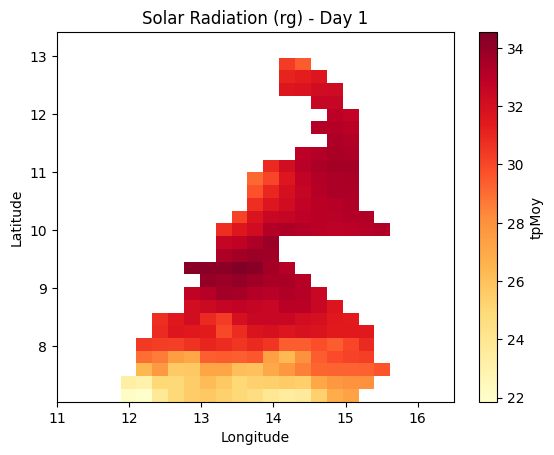

In [58]:
import matplotlib.pyplot as plt

# Select the first time step
base_data["tpMoy"].isel(time=6).plot(cmap="YlOrRd")
plt.title("Solar Radiation (rg) - Day 1")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [59]:
base_data = base_data.rename({'lat': 'y', 'lon': 'x'})
base_data 


<xarray.Dataset> Size: 4MB
Dimensions:   (time: 221, x: 25, y: 29)
Coordinates:
  * time      (time) datetime64[ns] 2kB 2008-04-01 2008-04-02 ... 2008-11-07
  * x         (x) float64 200B 11.11 11.33 11.55 11.77 ... 15.95 16.17 16.39
  * y         (y) float64 232B 7.15 7.37 7.59 7.81 ... 12.65 12.87 13.09 13.31
    quantile  float64 8B ...
Data variables:
    rain      (time, y, x) float64 1MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    tpMoy     (time, y, x) float32 641kB nan nan nan nan ... nan nan nan nan
    rg        (time, y, x) float64 1MB nan nan nan nan 21.02 ... nan nan nan nan
    ET0       (time, y, x) float64 1MB nan nan nan nan 12.84 ... nan nan nan nan

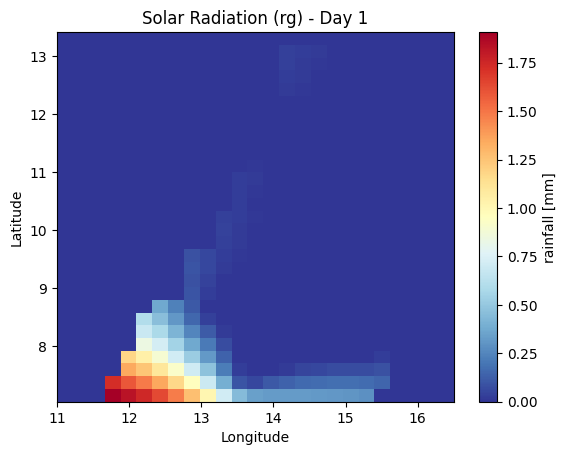

In [60]:
import matplotlib.pyplot as plt

# Select the first time step
base_data["rain"].isel(time=1).plot(cmap="RdYlBu_r")
plt.title("Solar Radiation (rg) - Day 1")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

All the loadings of these files was facilitated by the fact that they were already at the good units and homogeneous spatial projections and dimensions.

Now, we prepare the soil properties dataset. Here, we also cannot rely on the helper function load_iSDA_soil_data as it was destined to load data for the African continent (using iSDA Africa datasets). Here, we then replace this function call with a manual construction of dummy variables for soil properties in Brazil (i.e. the whole country will have homogeneous soil properties), for the purpose of testing. 


In [61]:
# # We initialize all the necessary variables with dummy values
# # Estimated soil properties from Brazil should be loaded here to get a more realistic simulation.

# # profile depth, 500 mm
# # here we take the first time step of the rainfall data as reference ot get the correct dimensions
# base_data["profRu"] = 500.0 * xr.ones_like(base_data["rain"][0,:,:]) 
# base_data["profRu"].attrs = {"units": "mm", "long_name": "Soil root zone depth (mm)"}

# # soil surface reservoir depth, 100 mm
# # then, we use profRu as a reference for the dimensions of invariant variables
# base_data["epaisseurSurf"] = 100.0 * xr.ones_like(base_data["profRu"])
# base_data["epaisseurSurf"].attrs = {"units": "mm", "long_name": "Soil surface reservoir depth (mm)"}

# # initial water stock in the soil surface reservoir, 50 mm (that sounds a lot)
# base_data["stockIniProf"] = 50.0 * xr.ones_like(base_data["profRu"])
# base_data["stockIniProf"].attrs = {"units": "mm", "long_name": "Initial water stock in the deep surface reservoir (mm)"}

# # runoff rate, 10%
# base_data["runoff_rate"] = 0.1 * xr.ones_like(base_data["profRu"])
# base_data["runoff_rate"].attrs = {"units": "mm", "long_name": "Runoff rate (mm)"}

# # runoff threshold, 10 mm 
# base_data["runoff_threshold"] = 10.0 * xr.ones_like(base_data["profRu"])

# # RZPAWC, root zone plant available water capacity, 100 mm
# base_data["RZPAWC"] = 100.0 * xr.ones_like(base_data["profRu"])
# base_data["RZPAWC"].attrs = {"units": "mm", "long_name": "Root zone plant available water capacity (mm)"}

# base_data["ru"] = base_data["RZPAWC"] / (base_data["profRu"]/1000)
# base_data["ru"].attrs = {"units": "mm", "long_name": "Root zone plant available water (mm)"}

# Check and set CRS if missing
if base_data.rio.crs is None:
    base_data = base_data.rio.write_crs("EPSG:4326")  # Replace with correct CRS if known

# Proceed with loading soil data and calculating day length
base_data = load_iSDA_soil_data_alternate(base_data, grid_width, grid_height)


Finally, we compute the day length, which is independent of parameters (and thus needs to be in the base dataset), and is needed in computations.

In [ ]:
# compute day length raster
base_data = calc_day_length_raster_fast(base_data, date_start, duration)

In [63]:
base_data

<xarray.Dataset> Size: 6MB
Dimensions:           (time: 221, x: 25, y: 29)
Coordinates:
  * time              (time) datetime64[ns] 2kB 2008-04-01 ... 2008-11-07
  * x                 (x) float64 200B 11.11 11.33 11.55 ... 15.95 16.17 16.39
  * y                 (y) float64 232B 7.15 7.37 7.59 7.81 ... 12.87 13.09 13.31
    quantile          float64 8B ...
    spatial_ref       int64 8B 0
Data variables: (12/13)
    rain              (time, y, x) float64 1MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    tpMoy             (time, y, x) float32 641kB nan nan nan nan ... nan nan nan
    rg                (time, y, x) float64 1MB nan nan nan nan ... nan nan nan
    ET0               (time, y, x) float64 1MB nan nan nan nan ... nan nan nan
    profRu            (y, x) float32 3kB 1.5e+03 1.5e+03 ... 1.5e+03 1.15e+03
    epaisseurSurf     (y, x) float32 3kB 200.0 200.0 200.0 ... 200.0 200.0 200.0
    ...                ...
    soil_type         (y, x) float32 3kB 4.0 6.0 6.0 4.0 4.0 ... 9.0 9.0 9.0 9.0
    runoff_threshold  (y, x) float32 3kB 12.0 15.0 15.0 12.0 ... 18.0 18.0 18.0
    runoff_rate       (y, x) float32 3kB 0.36 0.35 0.35 0.36 ... 0.32 0.32 0.32
    RZPAWC            (y, x) float32 3kB 121.0 136.0 119.0 ... 26.0 102.0 79.0
    ru                (y, x) float32 3kB 80.67 90.67 84.4 ... 65.0 68.0 68.7
    dureeDuJour       (time, y, x) float64 1MB 12.18 12.18 12.18 ... 11.58 11.58

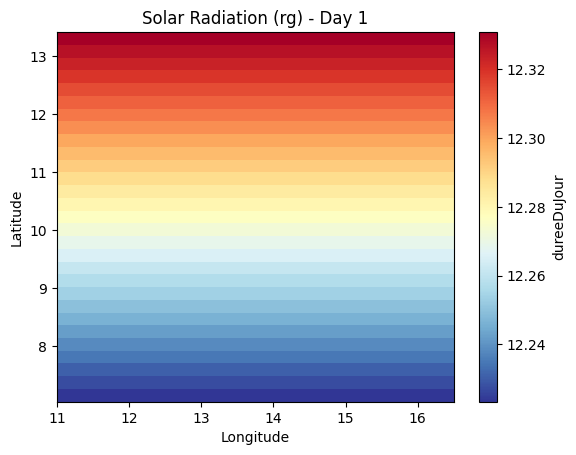

In [64]:
import matplotlib.pyplot as plt

# Select the first time step
base_data["dureeDuJour"].isel(time=6).plot(cmap="RdYlBu_r")
plt.title("Solar Radiation (rg) - Day 1")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

As we see below, the resulting base dataset is a `xarray.Dataset` object, which contains the rainfall and climate data, as well as the soil parameters. It also contains the day length, which is computed from the latitude of the location.

In [65]:
base_data

<xarray.Dataset> Size: 6MB
Dimensions:           (time: 221, x: 25, y: 29)
Coordinates:
  * time              (time) datetime64[ns] 2kB 2008-04-01 ... 2008-11-07
  * x                 (x) float64 200B 11.11 11.33 11.55 ... 15.95 16.17 16.39
  * y                 (y) float64 232B 7.15 7.37 7.59 7.81 ... 12.87 13.09 13.31
    quantile          float64 8B ...
    spatial_ref       int64 8B 0
Data variables: (12/13)
    rain              (time, y, x) float64 1MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    tpMoy             (time, y, x) float32 641kB nan nan nan nan ... nan nan nan
    rg                (time, y, x) float64 1MB nan nan nan nan ... nan nan nan
    ET0               (time, y, x) float64 1MB nan nan nan nan ... nan nan nan
    profRu            (y, x) float32 3kB 1.5e+03 1.5e+03 ... 1.5e+03 1.15e+03
    epaisseurSurf     (y, x) float32 3kB 200.0 200.0 200.0 ... 200.0 200.0 200.0
    ...                ...
    soil_type         (y, x) float32 3kB 4.0 6.0 6.0 4.0 4.0 ... 9.0 9.0 9.0 9.0
    runoff_threshold  (y, x) float32 3kB 12.0 15.0 15.0 12.0 ... 18.0 18.0 18.0
    runoff_rate       (y, x) float32 3kB 0.36 0.35 0.35 0.36 ... 0.32 0.32 0.32
    RZPAWC            (y, x) float32 3kB 121.0 136.0 119.0 ... 26.0 102.0 79.0
    ru                (y, x) float32 3kB 80.67 90.67 84.4 ... 65.0 68.0 68.7
    dureeDuJour       (time, y, x) float64 1MB 12.18 12.18 12.18 ... 11.58 11.58

## 3. Preparing a simulation dataset (`data`)

In this section, we will be loading simulation-specific parameters, and preparing a simulation dataset accordingly.

First, we will load the variety parameters file (`file_paramVariete`), the agricultural itinerary parameters file (`file_paramITK`) as well as the soil parameters file (`file_paramTypeSol`) by calling the `load_YAML_parameters` function. All these files can be found commented in the `./data/params/` folder. We incite you to make copies of the provided examples and play around with parameters by calling your copies.

In [ ]:
# parameter file names (files are located in the ../data/parameters/ folder)
file_paramVariete = "variety_exemple_2.yaml"
file_paramITK = "itk_exemple_2.yaml"
file_paramTypeSol = "USA_iowa_V42.yaml"

# populate param variables with variety, cropping system and soil parameters
parameters = load_model_parameters(
    f"../data/params/variety/{file_paramVariete}",
    f"../data/params/itk/{file_paramITK}",
    f"../data/params/soil/{file_paramTypeSol}",
)
paramVariete = dict(parameters.variety)
paramITK = dict(parameters.management)
paramTypeSol = dict(parameters.soil)

# we will force a value for the sowing date, so that we do not need to update the example file
paramITK["DateSemis"] = datetime.date(2008,5,1)

# on force les paramètres optimisés
paramVariete["SDJRPR"] = 489.0
paramVariete["SDJLevee"] = 250.0
paramVariete["SDJBVP"] = 636.0
paramVariete["slaMin"] = 285.0
paramVariete["slaMax"] = 363.2
paramVariete["SDJMatu1"] = 848.0
paramVariete["SDJMatu2"] = 334.0
paramVariete["KRdtPotA"] = 0.9








Once the parameters are loaded, we build up the simulation dataset `data` by copying the base dataset `base_data`, and feeding it with the simulation-specific parameters.

In [ ]:
simulation = SimulationConfig(date_start=date_start, duration=duration)
model_parameters = ModelParameters(paramVariete, paramITK, paramTypeSol)
validate_input_dataset(base_data, simulation)
data = base_data


In [ ]:
# Keep daily calendar coordinates for the validated API.
data = base_data


The resulting dataset `data` is a `xarray.Dataset` object, which contains all initialized variables for computations.

## 4. Running the model

Once the dataset is built, the model can be run by simply calling the `run_model` function. This function will perform the computations, and return an updated `xarray.Dataset` `data` object containing the results.

In [ ]:
data = run_sarra_simulation(base_data, model_parameters, simulation)


## 5. Mapping results

Display of the results is backed by the xarray plotting capacities. Because all intermediate calculation variables are stored in the `data` xarray object, we can plot whatever variable used in the calculation, for whatever time point. The list of variables which can be plotted can be accessed by displaying the contents of the data object, section "data variables".

In [70]:
data

<xarray.Dataset> Size: 70MB
Dimensions:                      (x: 25, y: 29, time: 221)
Coordinates:
  * x                            (x) float64 200B 11.11 11.33 ... 16.17 16.39
  * y                            (y) float64 232B 7.15 7.37 7.59 ... 13.09 13.31
    quantile                     float64 8B 0.9998
    spatial_ref                  int64 8B 0
Dimensions without coordinates: time
Data variables: (12/111)
    rain                         (time, y, x) float64 1MB 0.0 0.0 ... 0.0 0.0
    tpMoy                        (time, y, x) float32 641kB nan nan ... nan nan
    rg                           (time, y, x) float64 1MB nan nan ... nan nan
    ET0                          (time, y, x) float64 1MB nan nan ... nan nan
    profRu                       (y, x) float32 3kB 1.5e+03 1.5e+03 ... 1.15e+03
    epaisseurSurf                (y, x) float32 3kB 200.0 200.0 ... 200.0 200.0
    ...                           ...
    sumPP                        (time, y, x) float32 641kB 0.0 0.0 ... 0.0 0.0
    TigeUp                       (time, y, x) float32 641kB 0.0 0.0 ... 0.0 0.0
    UBTCulture                   (time, y, x) float32 641kB 0.0 0.0 ... 0.0 0.0
    lai                          (time, y, x) float32 641kB 0.0 0.0 ... 0.0 0.0
    Ncrit                        (time, y, x) float32 641kB nan nan ... 0.0 0.0
    irrigation                   (time, y, x) float64 1MB 0.0 0.0 ... 0.0 0.0

### 5.1 Plotting a time series of evolution of phenological phasing

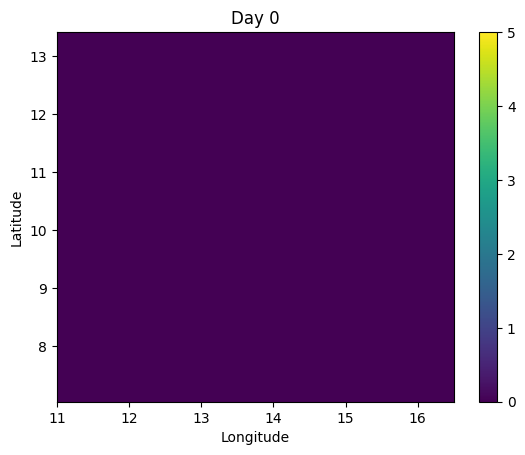

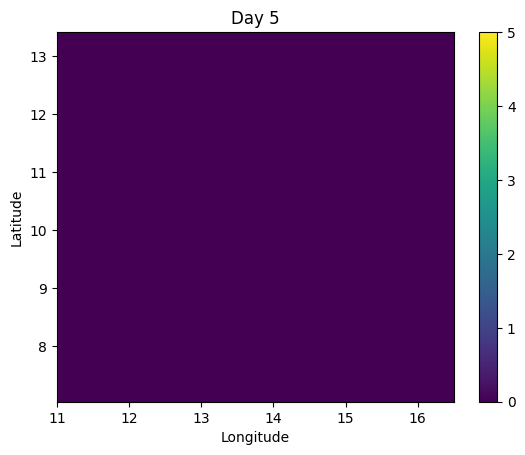

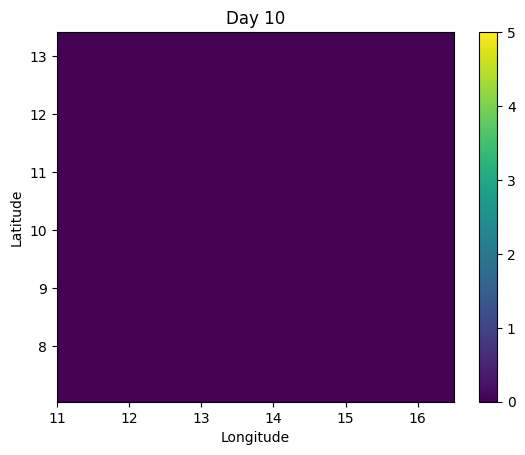

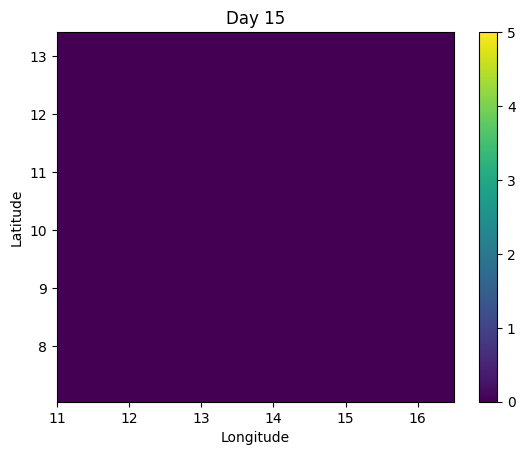

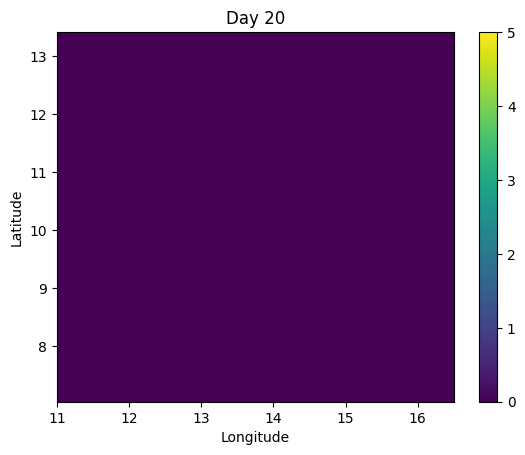

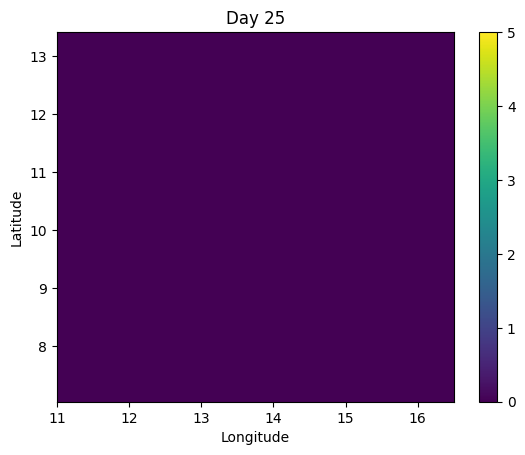

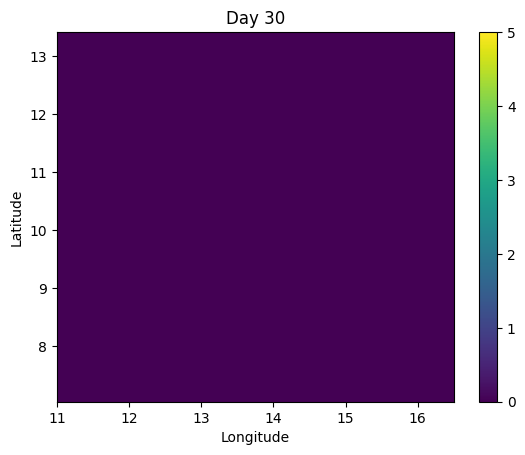

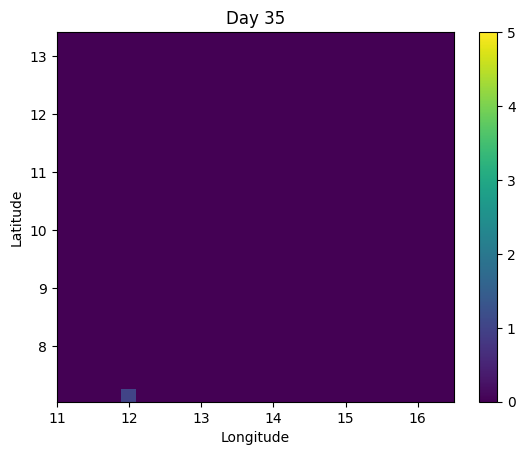

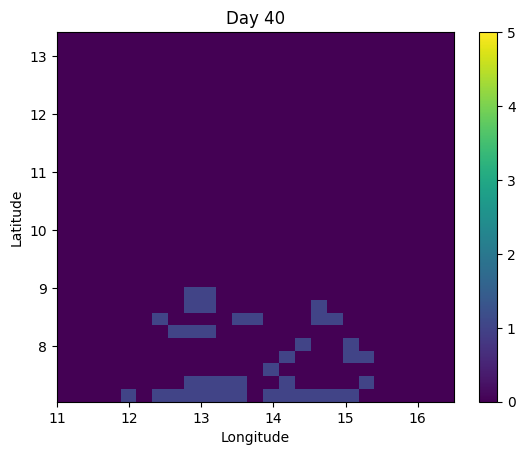

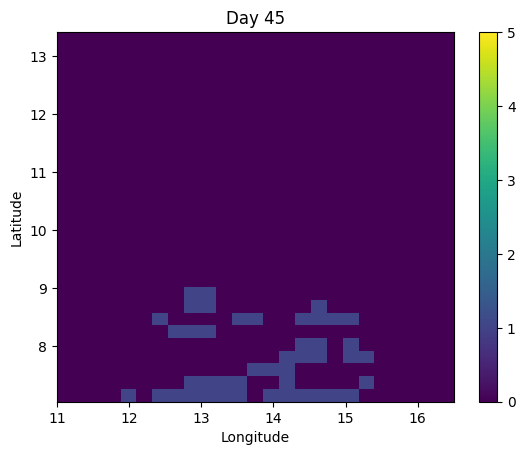

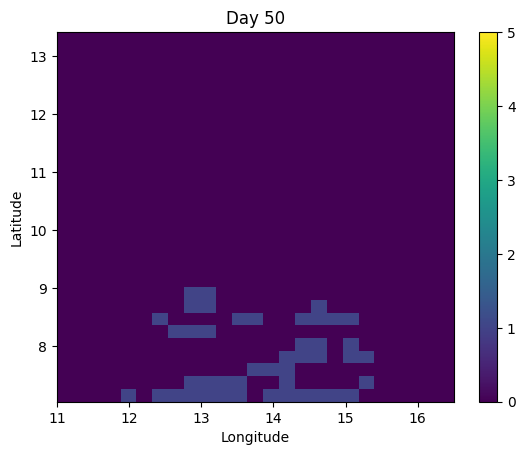

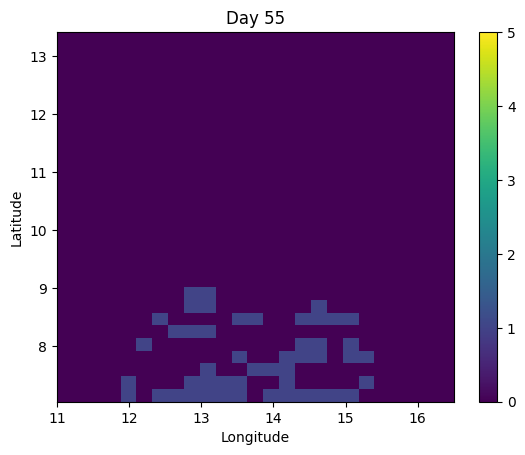

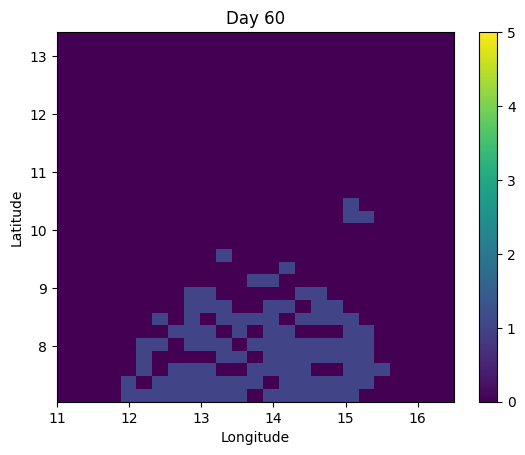

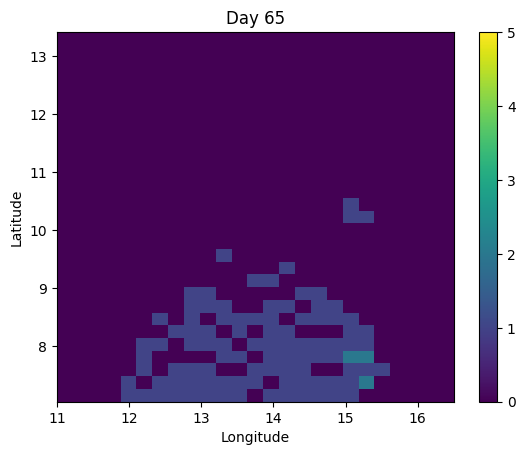

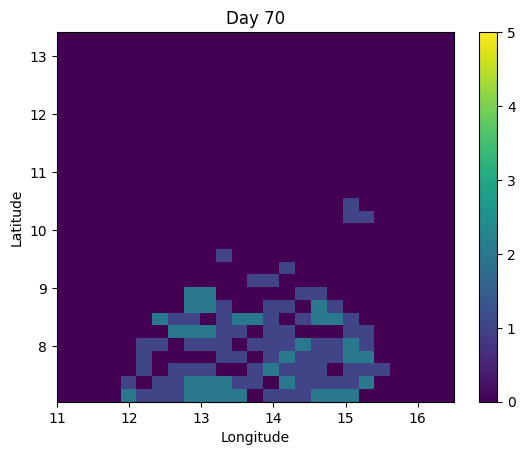

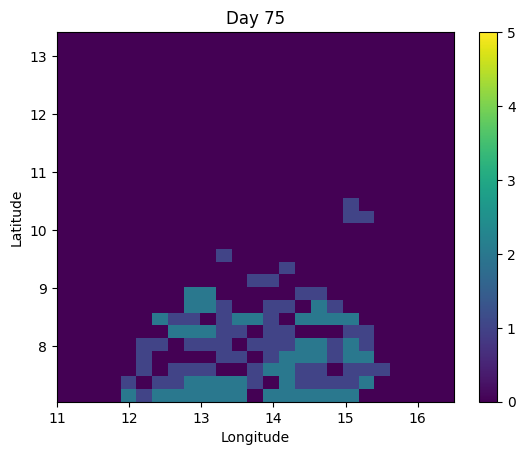

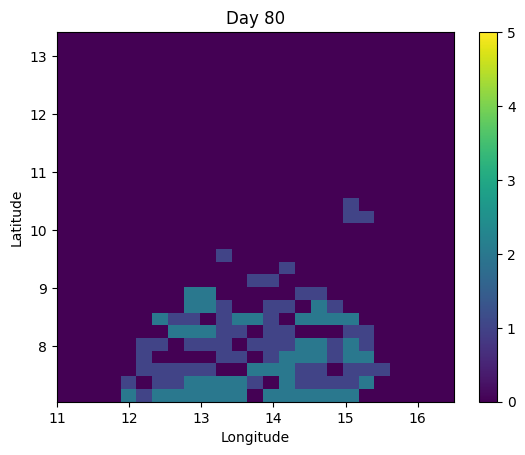

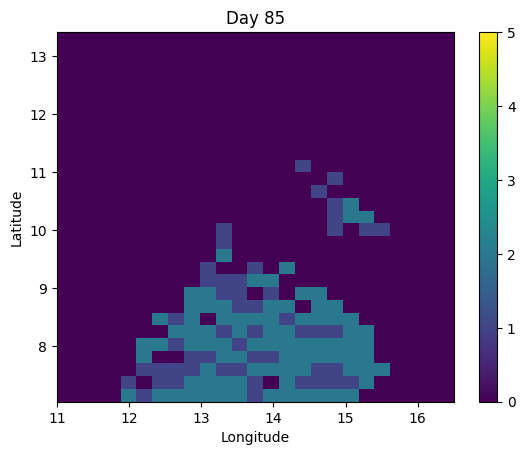

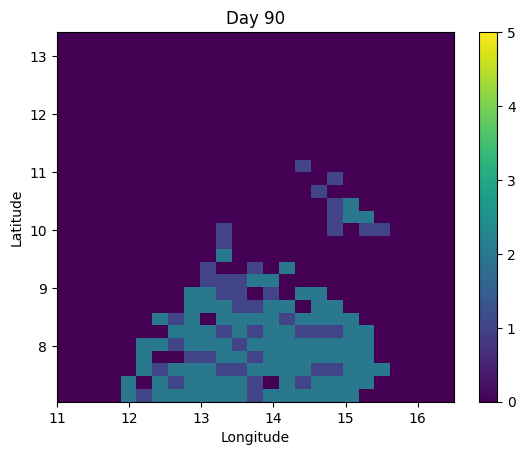

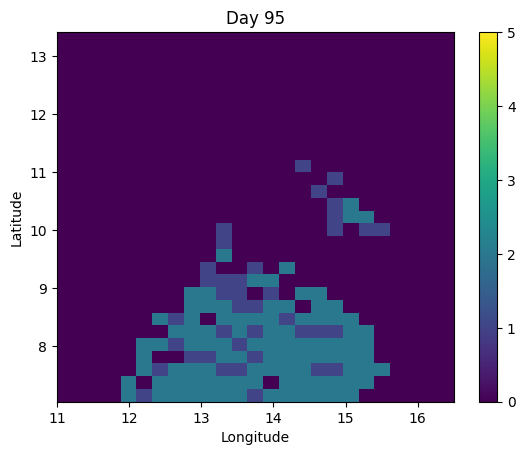

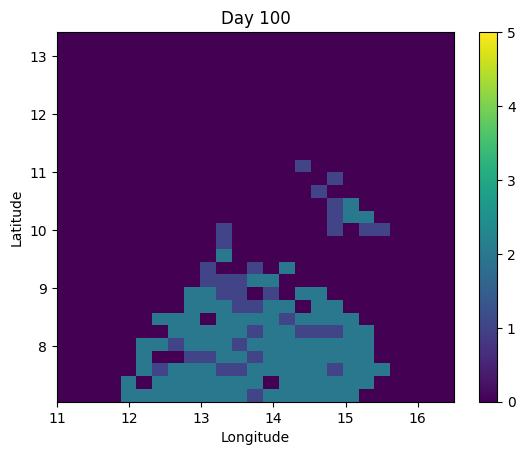

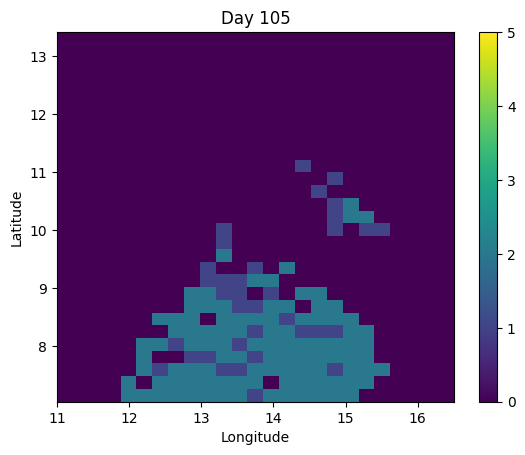

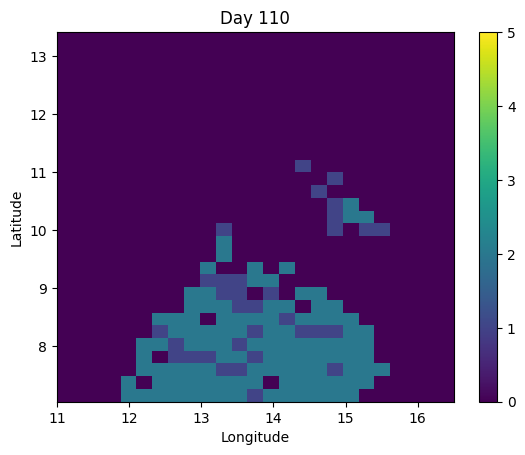

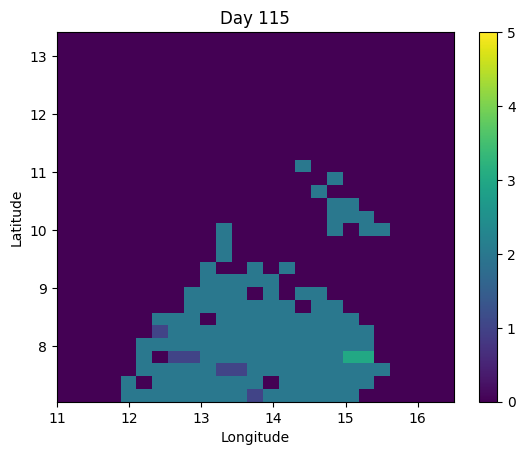

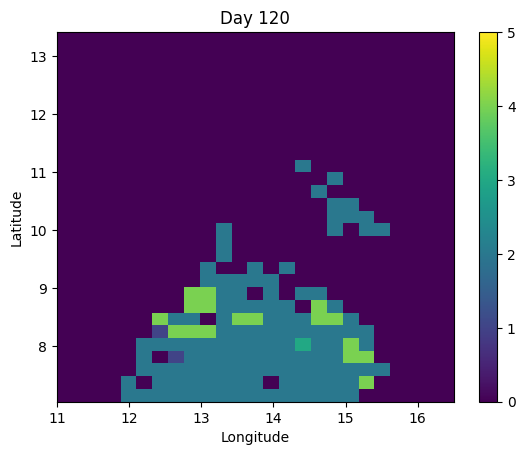

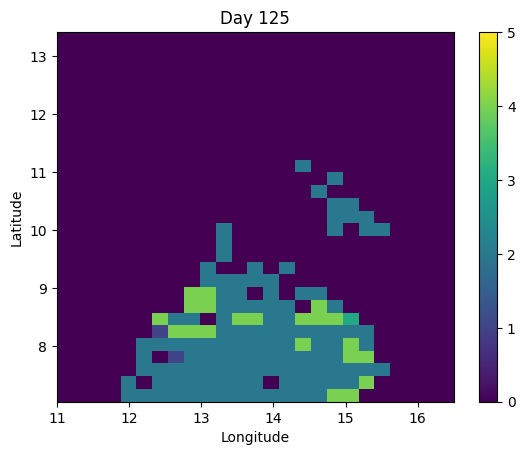

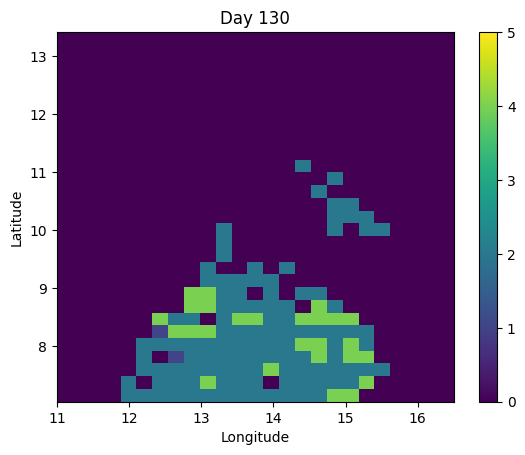

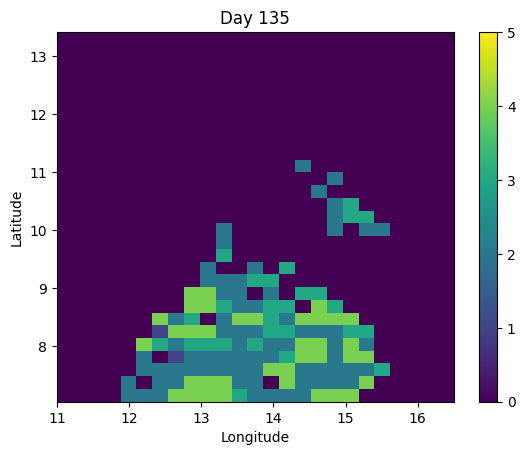

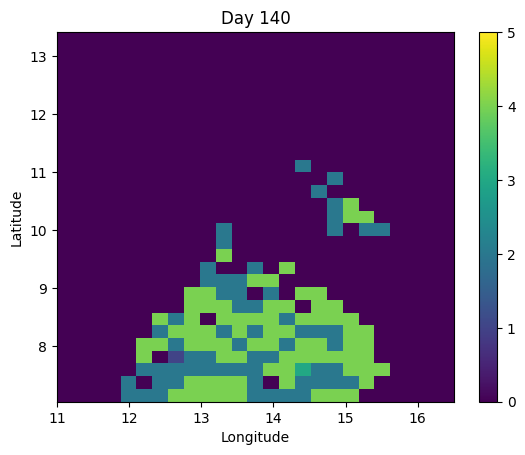

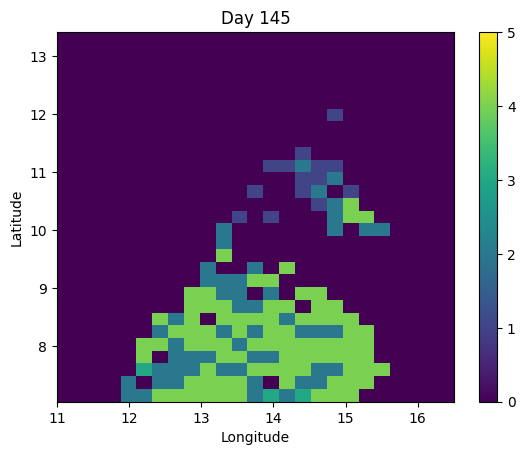

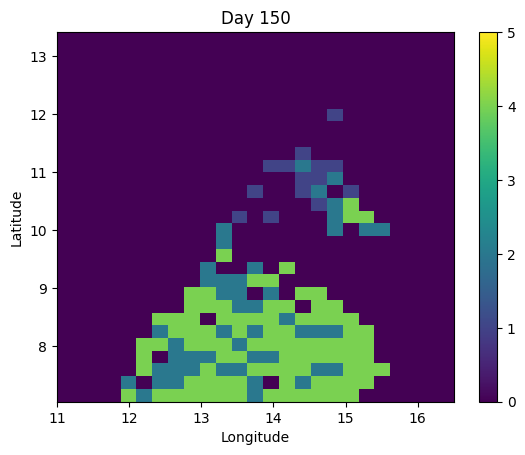

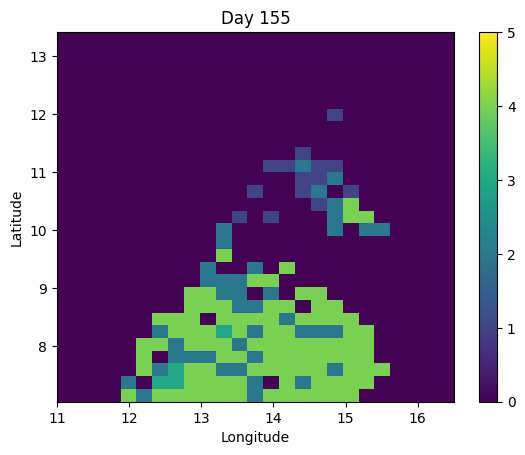

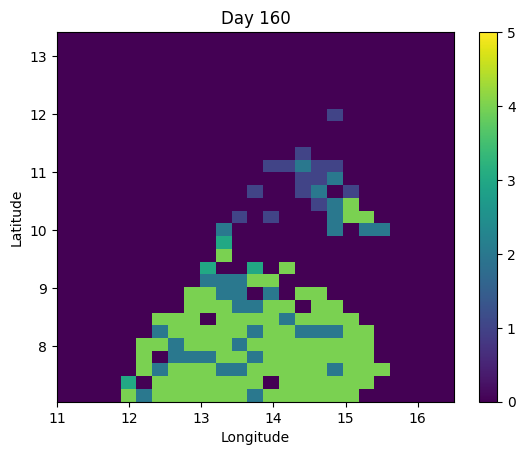

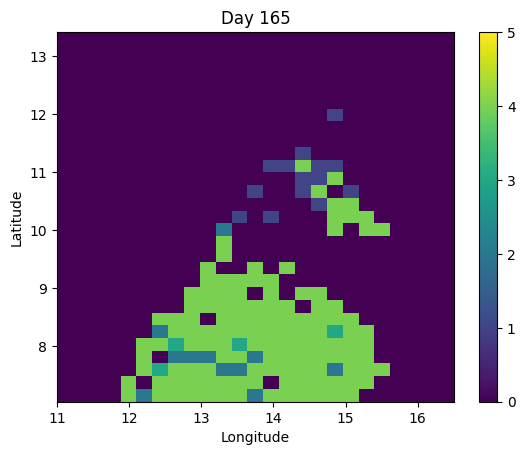

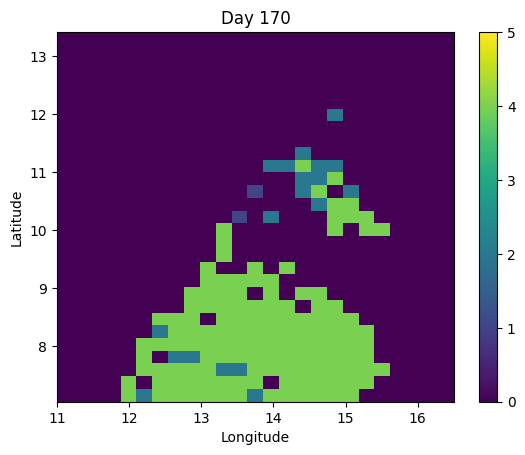

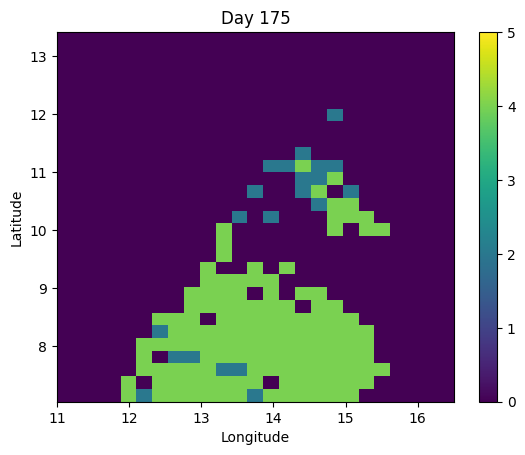

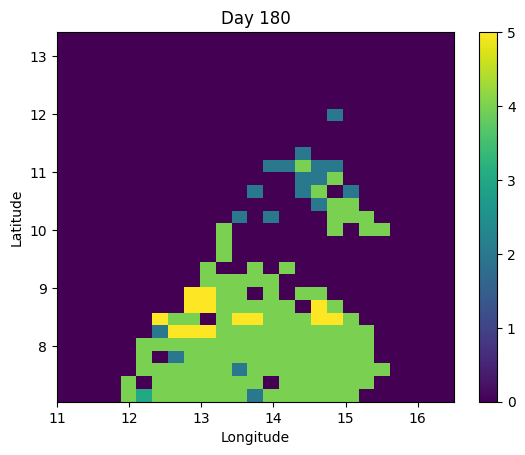

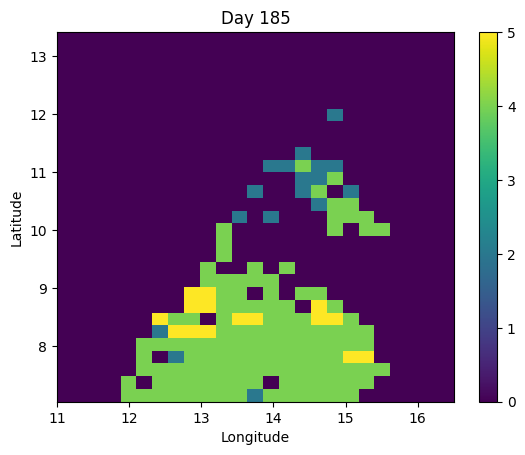

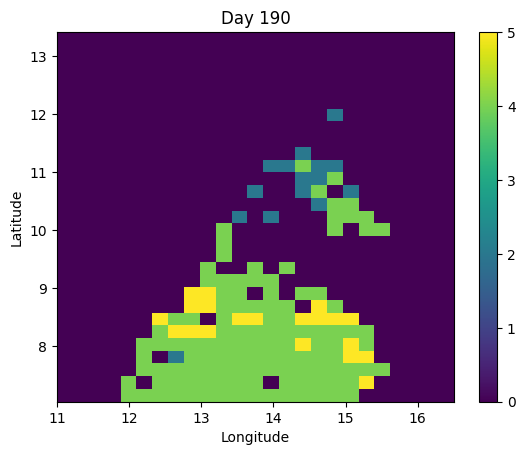

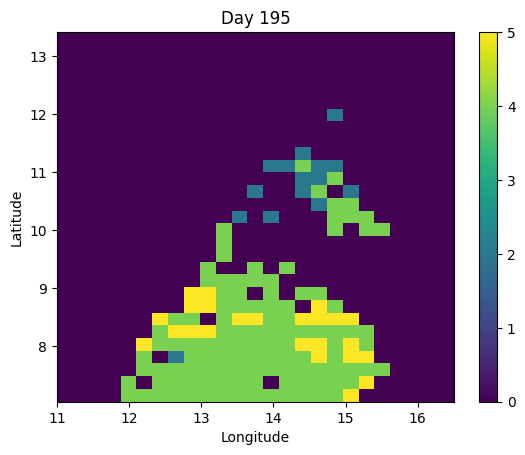

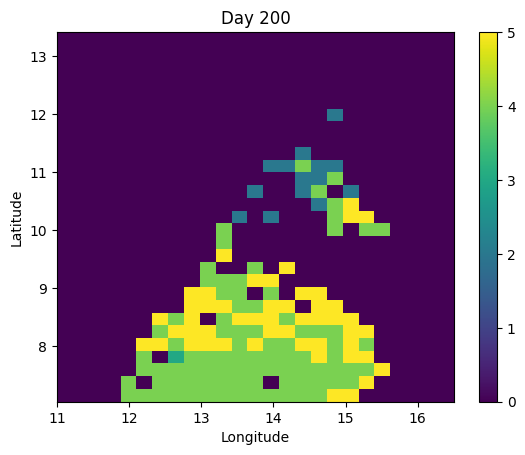

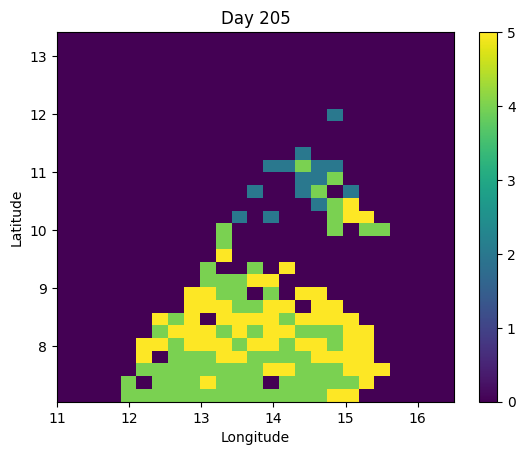

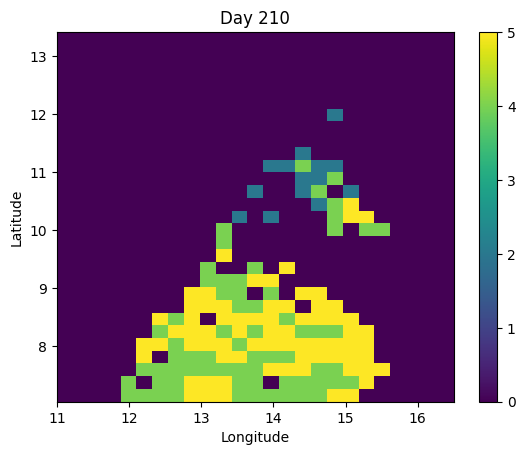

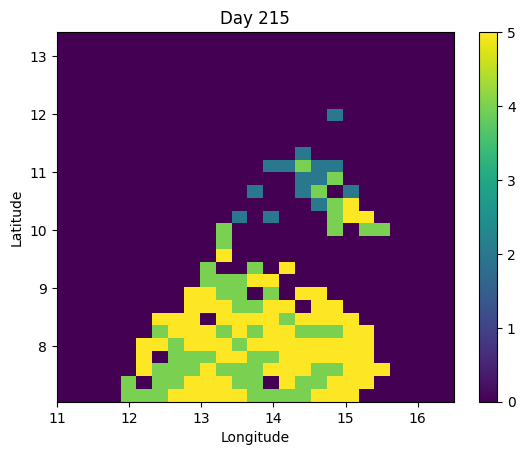

In [71]:
variable = "numPhase" # we define the variable we want to plot, here the number of phenological phase (0 to 7)
time_resolution = 5 # we will make a plot every 5 days
vmax = data[variable].max().values # we define the maximum value for the colorbar

# we loop over the time steps and plot the variable
for i in range(int(round(duration/time_resolution, 0))):
    xr.where(np.isnan(data["ru"]),np.nan,data[variable][time_resolution*i,:,:]).plot(vmin=0, vmax=vmax)
    plt.title("Day %s" % (i*time_resolution))
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.show()

### 5.2 Plotting endpoint simulated yield

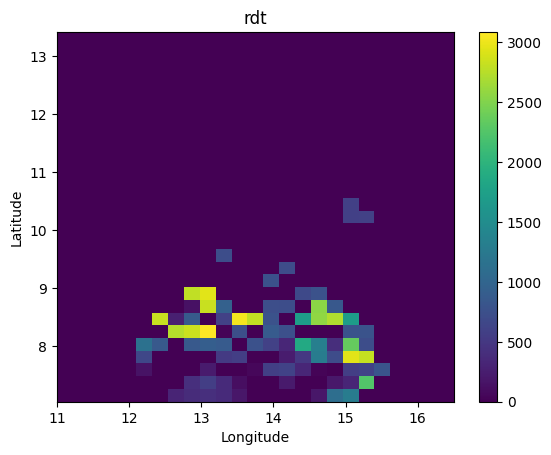

In [72]:
variable = "rdt" # we define the variable we want to plot, here the yield (rendement), in kg/ha

# we plot the variable at the last time step
xr.where(np.isnan(data["ru"]),np.nan,data[variable][-1,:,:]).plot()
plt.title("%s" % (variable))
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()